# E4 Feature Fusion: Acoustic, Whisper, and Combined Features

Do acoustic features add useful information beyond frozen Whisper features?

This run uses the existing 2,000 audio clips. Label 1 is MNSC / Singapore.
Label 0 is Common Voice / non-Singapore. Corpus and class are linked.
High scores do not establish accent recognition under new recording conditions.

All six matched notebooks use one saved clip list and one speaker split.
Training and validation select settings. Test speakers measure the fixed model.
The first grouped fold supplies test data. This is **one split**, not full cross-validation.

Shared implementation: [experiment_common.py](experiment_common.py).
Read its audio and evaluation functions to inspect the full procedure.
The original notebooks were backed up before this update.

## 1. Use the local audio environment

Use the **Singlish audio review (Python 3.12)** kernel.
Dependencies are already installed. This notebook does not upgrade packages.
Set the two paths below if the project moves.

In [1]:
from pathlib import Path
import sys

USE_GOOGLE_DRIVE = False
if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = Path('/content/drive/MyDrive/Singlish')
    DATA_ROOT = PROJECT_ROOT / 'data' / 'audio'
else:
    PROJECT_ROOT = Path('/home/mh/nusproj/singlish-whisper')
    DATA_ROOT = PROJECT_ROOT / 'data' / 'e1_audio_1000x2' / 'data'

sys.path.insert(0, str(PROJECT_ROOT / 'notebooks'))
import experiment_common as common
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone

%matplotlib inline
config = common.configure(PROJECT_ROOT, DATA_ROOT)
print('Audio:', DATA_ROOT)
print('Results:', config['output'])
print(json.dumps(common.environment(), indent=2))

Audio: /home/mh/nusproj/singlish-whisper/data/e1_audio_1000x2/data
Results: /home/mh/nusproj/singlish-whisper/outputs/matched_2000_seed42
{
  "python": "3.12.13",
  "packages": {
    "numpy": "2.5.1",
    "scipy": "1.18.0",
    "scikit-learn": "1.9.0",
    "librosa": "1.0.0",
    "torch": "2.13.0+cu126",
    "transformers": "4.57.6",
    "nbclient": "0.11.0"
  }
}


## 2. Verify clips and load the shared split

File hashes detect duplicate audio. Extraction failures stop the run.
No notebook silently drops clips or creates a different test set.
Each speaker stays in one partition. The split is approximately 64% / 16% / 20%.
The saved split remains fixed on later runs.

In [2]:
frame, fingerprint = common.prepare_manifest(config)
split = common.shared_split(config, frame, fingerprint)
y = frame.label.to_numpy()
groups = frame.group.to_numpy(dtype=str)
train_idx, val_idx, test_idx = (split[name] for name in ['train', 'validation', 'test'])
trainval_idx = np.sort(np.r_[train_idx, val_idx])
assert set(groups[train_idx]).isdisjoint(groups[test_idx])
assert set(groups[val_idx]).isdisjoint(groups[test_idx])

Clips: {0: 1000, 1: 1000}
Speakers: {0: 300, 1: 583}
Dataset SHA256: 872f8ffa700bb810105b9796d6c0032c6d8c07bd9b3ffedfb6239a179d6fa8cb


{
  "train": {
    "clips": 1280,
    "speakers": 566,
    "label_counts": {
      "0": 640,
      "1": 640
    }
  },
  "validation": {
    "clips": 320,
    "speakers": 141,
    "label_counts": {
      "0": 160,
      "1": 160
    }
  },
  "test": {
    "clips": 400,
    "speakers": 176,
    "label_counts": {
      "0": 200,
      "1": 200
    }
  }
}
Speaker overlap: 0. This is one fixed grouped split, not five-fold evaluation.


## 3. Extract both representations from the same clips

There are 39 acoustic features and 512 frozen Whisper features.
The shared extractor uses the same waveform for both branches.
Whisper pooling excludes the padded tail. The full feature cache is reused by E1 and E2.

In [3]:
A, W = common.load_features(config, frame, fingerprint, whisper=True)

/home/mh/miniconda3/envs/audioenv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Acoustic extraction: 100/2000


Acoustic extraction: 200/2000


Acoustic extraction: 300/2000


Acoustic extraction: 400/2000


...

Whisper extraction: 1616/2000


Whisper extraction: 1776/2000


Whisper extraction: 1936/2000


Whisper extraction: 2000/2000


Whisper features: (2000, 512)


## 4. Fit preprocessing on fitting speakers only

Scale each block separately. Reduce Whisper to 32 PCA columns for the fusion branch.
Standardize the PCA columns. Divide each fused block by the square root of its column count.
This balances total block scale. Each classifier selects its own regularization.
Also test full Whisper without PCA. This checks whether PCA hides a stronger single branch.
PCA dimension 32 is fixed before evaluation. This run does not search for the best dimension.

In [4]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression

PCA_DIMENSIONS = 32
C_VALUES = [0.01, 0.1, 1.0, 10.0, 100.0]

def make_feature_views(fit_idx):
    acoustic_scaler = StandardScaler().fit(A[fit_idx])
    a = acoustic_scaler.transform(A)
    whisper_scaler = StandardScaler().fit(W[fit_idx])
    w_full = whisper_scaler.transform(W)
    pca = PCA(n_components=PCA_DIMENSIONS, svd_solver='full').fit(w_full[fit_idx])
    w_pca = pca.transform(w_full)
    pca_scaler = StandardScaler().fit(w_pca[fit_idx])
    w = pca_scaler.transform(w_pca)
    fused = np.column_stack([a / np.sqrt(a.shape[1]), w / np.sqrt(w.shape[1])])
    views = {'Acoustic': a, 'Whisper full': w_full, 'Whisper PCA': w, 'Feature fusion': fused}
    transforms = {'acoustic_scaler': acoustic_scaler, 'whisper_scaler': whisper_scaler,
                  'whisper_pca': pca, 'pca_scaler': pca_scaler}
    return views, transforms

validation_views, _ = make_feature_views(train_idx)
print({name: matrix.shape for name, matrix in validation_views.items()})

{'Acoustic': (2000, 39), 'Whisper full': (2000, 512), 'Whisper PCA': (2000, 32), 'Feature fusion': (2000, 71)}


## 5. Select C using validation speakers

All four heads use logistic regression and the same C choices.
Macro F1 selects settings. Balanced accuracy breaks ties.
Select the primary single-branch comparator on validation, before viewing test scores.

In [5]:
selected_models, validations = {}, {}
for name, matrix in validation_views.items():
    print('\n', name)
    candidates = [(f'C={c:g}', LogisticRegression(C=c, class_weight='balanced', max_iter=5000,
                   random_state=common.SEED)) for c in C_VALUES]
    selected_models[name], validations[name] = common.choose_candidate(candidates, matrix, y, split)

single_names = ['Acoustic', 'Whisper full', 'Whisper PCA']
primary_comparator = max(single_names, key=lambda name: (
    validations[name]['selected']['macro_f1'], validations[name]['selected']['balanced_accuracy']))
common.write_json(config['output'] / 'feature_fusion' / 'validation_selection.json',
                  {'primary_comparator': primary_comparator, 'models': validations})
print('Primary comparator, selected on validation:', primary_comparator)


 Acoustic


candidate  macro_f1  balanced_accuracy
   C=0.01  0.924997           0.925000
    C=0.1  0.928124           0.928125
      C=1  0.928124           0.928125
     C=10  0.903124           0.903125
    C=100  0.900000           0.900000
Validation choice: C=0.1

 Whisper full


candidate  macro_f1  balanced_accuracy
   C=0.01  0.962499           0.962500
    C=0.1  0.953114           0.953125
      C=1  0.956243           0.956250
     C=10  0.940597           0.940625
    C=100  0.931226           0.931250
Validation choice: C=0.01

 Whisper PCA
candidate  macro_f1  balanced_accuracy
   C=0.01  0.924988           0.925000
    C=0.1  0.924988           0.925000
      C=1  0.915604           0.915625
     C=10  0.915604           0.915625
    C=100  0.915604           0.915625
Validation choice: C=0.01

 Feature fusion


candidate  macro_f1  balanced_accuracy
   C=0.01  0.943750           0.943750
    C=0.1  0.956248           0.956250
      C=1  0.959375           0.959375
     C=10  0.965625           0.965625
    C=100  0.953114           0.953125
Validation choice: C=10
Primary comparator, selected on validation: Whisper full


## 6. Refit transforms and heads, then evaluate test speakers

C is fixed. Refit scaling, PCA, and each head on training plus validation speakers.
Evaluate all four models on the same test clips.
This is logistic-regression feature fusion. It is not a rerun of the report's SVM fusion.

{
  "accuracy": 0.9325,
  "macro_f1": 0.9324793217922989,
  "balanced_accuracy": 0.9325,
  "roc_auc": 0.9729,
  "errors": 27,
  "confusion_matrix": [
    [
      183,
      17
    ],
    [
      10,
      190
    ]
  ],
  "confusion_matrix_labels": [
    0,
    1
  ],
  "brier_score": 0.05339309573173523,
  "speaker_bootstrap_ci95": {
    "accuracy": [
      0.8954392203782894,
      0.9633258234232389
    ],
    "balanced_accuracy": [
      0.8959362887815594,
      0.9632394541602816
    ],
    "macro_f1": [
      0.895435315825532,
      0.9633251951107756
    ]
  }
}


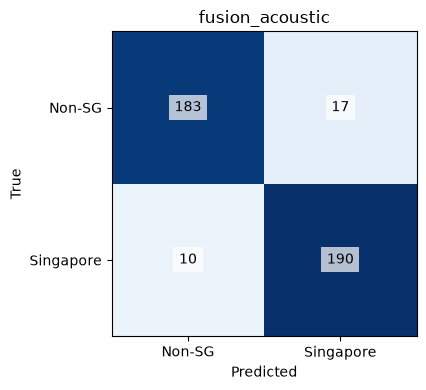

{
  "accuracy": 0.9825,
  "macro_f1": 0.9824998906243163,
  "balanced_accuracy": 0.9824999999999999,
  "roc_auc": 0.99785,
  "errors": 7,
  "confusion_matrix": [
    [
      196,
      4
    ],
    [
      3,
      197
    ]
  ],
  "confusion_matrix_labels": [
    0,
    1
  ],
  "brier_score": 0.01893358863890171,
  "speaker_bootstrap_ci95": {
    "accuracy": [
      0.9659077050997783,
      0.9950983388465411
    ],
    "balanced_accuracy": [
      0.9658701939940278,
      0.9950985905681276
    ],
    "macro_f1": [
      0.9658526834491921,
      0.9950764856142932
    ]
  }
}


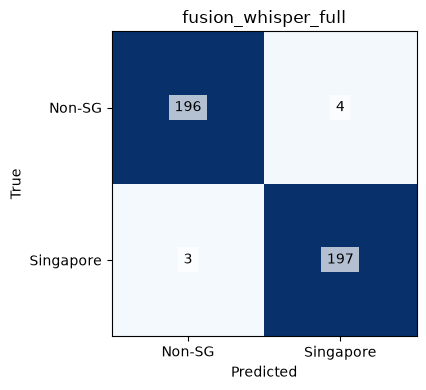

{
  "accuracy": 0.97,
  "macro_f1": 0.97,
  "balanced_accuracy": 0.97,
  "roc_auc": 0.993125,
  "errors": 12,
  "confusion_matrix": [
    [
      194,
      6
    ],
    [
      6,
      194
    ]
  ],
  "confusion_matrix_labels": [
    0,
    1
  ],
  "brier_score": 0.05775163695216179,
  "speaker_bootstrap_ci95": {
    "accuracy": [
      0.9518003134988935,
      0.9856459330143541
    ],
    "balanced_accuracy": [
      0.9514242817950177,
      0.9855984488821525
    ],
    "macro_f1": [
      0.9516285353255834,
      0.985569431691956
    ]
  }
}


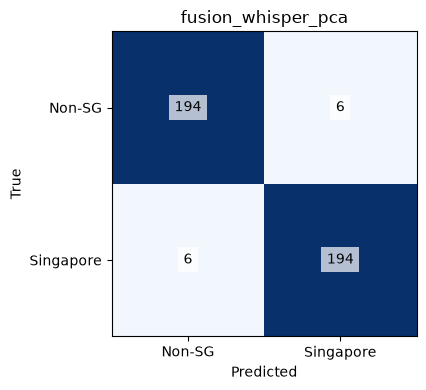

{
  "accuracy": 0.98,
  "macro_f1": 0.9799954989872721,
  "balanced_accuracy": 0.98,
  "roc_auc": 0.9956999999999999,
  "errors": 8,
  "confusion_matrix": [
    [
      193,
      7
    ],
    [
      1,
      199
    ]
  ],
  "confusion_matrix_labels": [
    0,
    1
  ],
  "brier_score": 0.01725558148748453,
  "speaker_bootstrap_ci95": {
    "accuracy": [
      0.955881398013751,
      0.9974683544303797
    ],
    "balanced_accuracy": [
      0.9554061099109464,
      0.9974358974358974
    ],
    "macro_f1": [
      0.9557233972759528,
      0.9974660677189437
    ]
  }
}


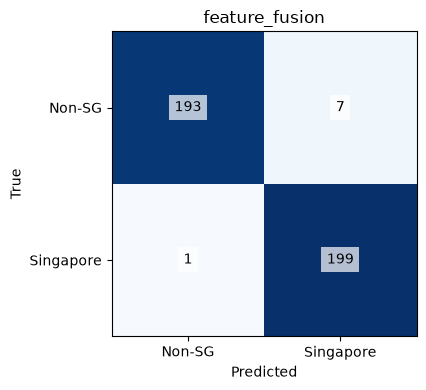

['/home/mh/nusproj/singlish-whisper/outputs/matched_2000_seed42/feature_fusion/fusion_models.joblib']

In [6]:
final_views, preprocessors = make_feature_views(trainval_idx)
models, reports, predictions = {}, {}, {}
output_names = {'Acoustic':'fusion_acoustic', 'Whisper full':'fusion_whisper_full',
                'Whisper PCA':'fusion_whisper_pca', 'Feature fusion':'feature_fusion'}
for name, matrix in final_views.items():
    model = clone(selected_models[name]).fit(matrix[trainval_idx], y[trainval_idx])
    models[name] = model
    predicted = model.predict(matrix[test_idx])
    scores = model.predict_proba(matrix[test_idx])[:, 1]
    predictions[name] = predicted
    reports[name] = common.save_result(config, output_names[name], frame, fingerprint, split,
        None, predicted, scores, validations[name], probability=True,
        extra={'encoder': common.MODEL_NAME, 'encoder_frozen': True,
               'pooling': 'mean over real audio encoder steps',
               'pca_dimensions': PCA_DIMENSIONS, 'feature_columns': matrix.shape[1],
               'primary_comparator': primary_comparator})

joblib.dump({'preprocessors':preprocessors, 'models':models, 'encoder':common.MODEL_NAME,
             'pca_dimensions':PCA_DIMENSIONS, 'block_normalization':'divide by sqrt(column count)'},
            config['output'] / 'feature_fusion' / 'fusion_models.joblib')

## 7. Compare paired results and show uncertainty

The same test speakers enter both sides of each difference.
Resample speakers within each class, using the same draw for both models.
An interval that includes zero does not establish an improvement.
These intervals do not account for training-split variation.

{
  "Acoustic": {
    "macro_f1": {
      "difference": 0.04751617719497325,
      "ci95": [
        0.022550283401914926,
        0.07488239770020542
      ]
    },
    "balanced_accuracy": {
      "difference": 0.04749999999999999,
      "ci95": [
        0.022499429434986395,
        0.07501480107264522
      ]
    }
  },
  "Whisper full": {
    "macro_f1": {
      "difference": -0.00250439163704419,
      "ci95": [
        -0.024466487806945166,
        0.01821254138144728
      ]
    },
    "balanced_accuracy": {
      "difference": -0.0024999999999999467,
      "ci95": [
        -0.02465980322356478,
        0.01792939916929103
      ]
    }
  },
  "Whisper PCA": {
    "macro_f1": {
      "difference": 0.009995498987272144,
      "ci95": [
        -0.012907728513796993,
        0.031924080331941516
      ]
    },
    "balanced_accuracy": {
      "difference": 0.010000000000000009,
      "ci95": [
        -0.012757320768113058,
        0.03209435115005773
      ]
    }
  }
}


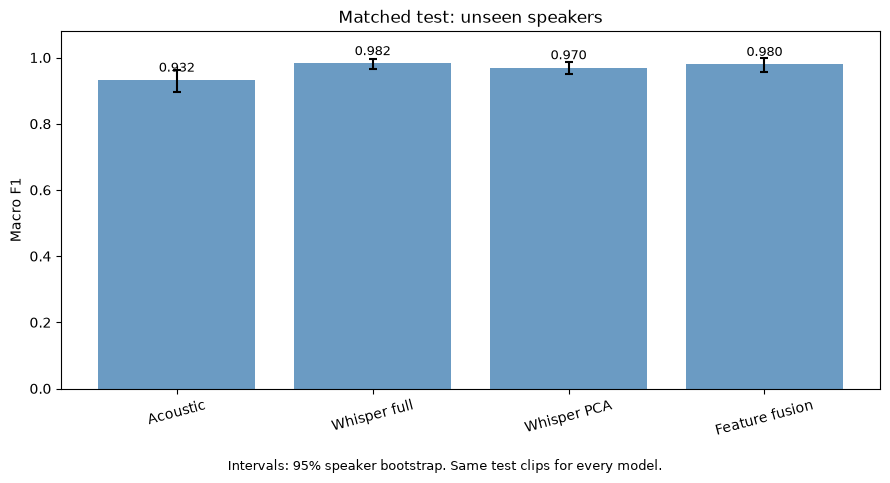

,accuracy,balanced_accuracy,macro_f1,roc_auc,errors
Acoustic,0.9325,0.9325,0.932479,0.972900,27.0
Whisper full,0.9825,0.9825,0.982500,0.997850,7.0
Whisper PCA,0.9700,0.9700,0.970000,0.993125,12.0
Feature fusion,0.9800,0.9800,0.979995,0.995700,8.0


In [7]:
paired = {}
for name in single_names:
    paired[name] = common.paired_intervals(y[test_idx], predictions['Feature fusion'],
                                          predictions[name], groups[test_idx])
common.write_json(config['output'] / 'feature_fusion' / 'paired_differences.json',
                  {'primary_comparator':primary_comparator, 'fusion_minus_single':paired})
print(json.dumps(paired, indent=2))
common.comparison_chart(reports, config['output'] / 'feature_fusion' / 'fusion_comparison.png')
display(pd.DataFrame({name:{key:report['test'][key] for key in
    ['accuracy','balanced_accuracy','macro_f1','roc_auc','errors']} for name,report in reports.items()}).T)

## Interpretation

Use the validation-selected comparator for the primary fusion claim.
Report all single-branch scores. A gain over a weak branch alone is insufficient.
Do not change C or PCA after inspecting test results.
Corpus, microphone, prompt, and speaker differences remain alternative explanations.
The next external check should use Singapore and non-Singapore clips from comparable recording sources.

## Recorded result: 28 October 2026

Accuracy: **98.00%**. Macro F1: **0.9800**.
There were **8 errors among 400 test clips** from 176 speakers.
Non-Singapore clips predicted as Singapore: **7**.
Singapore clips predicted as non-Singapore: **1**.
The 95% speaker-bootstrap interval for macro F1 is **[0.9557, 0.9975]**.

Validation selected **Whisper full** as the primary single-branch comparator.
Full Whisper made seven test errors. Feature fusion made eight.
Fusion minus full Whisper: macro F1 **-0.0025**.
The paired 95% interval is **[-0.0245, +0.0182]**.
The interval includes zero. This run does not establish a fusion gain.
Fusion improves on acoustic-only features here. It does not improve on the full Whisper control.

Class and corpus remain linked. These scores do not isolate accent from recording-source effects.
Artifacts: `../outputs/matched_2000_seed42/feature_fusion/`.